# LDA (Linear Discriminant Analysis)

## ¿Cuál es el objetivo de LDA?

El **Análisis Discriminante Lineal (LDA)** es un algoritmo de **reducción de dimensionalidad supervisado**. Al igual que PCA, transforma datos de alta dimensionalidad a un espacio de menor dimensión. Pero a diferencia de PCA, LDA **usa las etiquetas de clase** para encontrar las mejores direcciones de proyección.

El objetivo de LDA es encontrar la proyección que **maximiza la separación entre clases** y al mismo tiempo **minimiza la dispersión dentro de cada clase**:

$$
\mathbf{w}^* = \arg\max_{\mathbf{w}} \frac{\mathbf{w}^T \mathbf{S}_B \mathbf{w}}{\mathbf{w}^T \mathbf{S}_W \mathbf{w}}
$$

Donde:

- $\mathbf{S}_B$: **scatter matrix entre clases** (between-class). Mide qué tan separadas están las medias de cada clase.
- $\mathbf{S}_W$: **scatter matrix dentro de clases** (within-class). Mide qué tan dispersos están los datos dentro de cada clase.

Este cociente se llama el **criterio de Fisher** o **Rayleigh quotient**.

**PCA vs LDA:**

| | PCA | LDA |
|---|---|---|
| Tipo | No supervisado | Supervisado |
| Objetivo | Maximizar varianza total | Maximizar separación entre clases |
| Usa etiquetas | No | Sí |
| Máx. componentes | $d$ (features) | $C - 1$ (clases - 1) |
| Mejor para | Reducir dimensionalidad general | Reducir para clasificación |

**Supongamos un conjunto de datos simples**

Consideremos datos en 2D con dos clases:

| $x_1$ | $x_2$ | Clase |
|-------|-------|-------|
| 1     | 2     | 0     |
| 2     | 3     | 0     |
| 3     | 3     | 0     |
| 2     | 1     | 0     |
| 6     | 7     | 1     |
| 7     | 8     | 1     |
| 8     | 7     | 1     |
| 7     | 6     | 1     |

PCA encontraría la dirección de mayor varianza total (la diagonal), pero LDA busca la dirección que **mejor separe** las dos clases. A veces estas coinciden, pero no siempre.

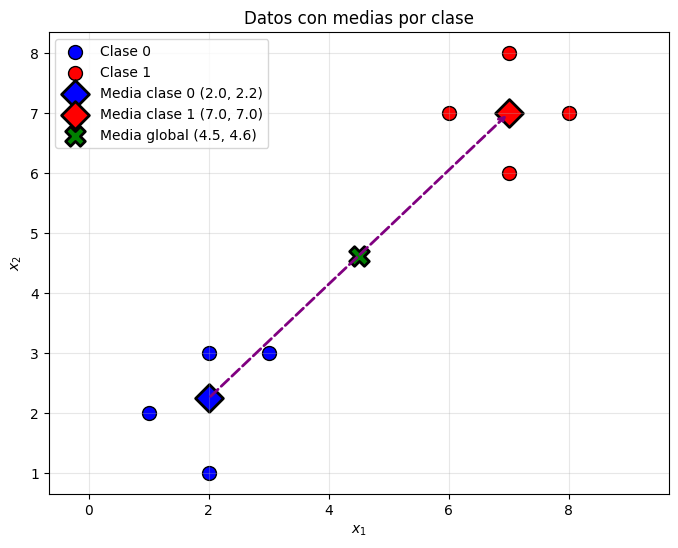

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

# Datos de ejemplo
X = np.array([[1, 2], [2, 3], [3, 3], [2, 1],
              [6, 7], [7, 8], [8, 7], [7, 6]])
y = np.array([0, 0, 0, 0, 1, 1, 1, 1])

# Medias
mean_0 = X[y == 0].mean(axis=0)
mean_1 = X[y == 1].mean(axis=0)
mean_all = X.mean(axis=0)

plt.figure(figsize=(8, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1], color='blue', s=100, label='Clase 0', edgecolors='black')
plt.scatter(X[y == 1, 0], X[y == 1, 1], color='red', s=100, label='Clase 1', edgecolors='black')
plt.scatter(*mean_0, color='blue', marker='D', s=200, edgecolors='black', linewidths=2, label=f'Media clase 0 ({mean_0[0]:.1f}, {mean_0[1]:.1f})')
plt.scatter(*mean_1, color='red', marker='D', s=200, edgecolors='black', linewidths=2, label=f'Media clase 1 ({mean_1[0]:.1f}, {mean_1[1]:.1f})')
plt.scatter(*mean_all, color='green', marker='X', s=200, edgecolors='black', linewidths=2, label=f'Media global ({mean_all[0]:.1f}, {mean_all[1]:.1f})')

# Flecha entre medias
plt.annotate('', xy=mean_1, xytext=mean_0,
             arrowprops=dict(arrowstyle='->', color='purple', lw=2, linestyle='--'))

plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.title('Datos con medias por clase')
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left')
plt.axis('equal')
plt.show()

## ¿Cómo encuentra LDA la mejor proyección?

LDA busca una dirección $\mathbf{w}$ tal que al proyectar los datos sobre ella:

- Las **medias proyectadas** de cada clase estén lo más **separadas** posible.
- Los **datos proyectados** dentro de cada clase estén lo más **compactos** posible.

Visualmente: queremos que los "nubes" de cada clase se vean lo más alejadas y lo más apretadas posible al proyectar sobre una línea.

La clave está en las dos **scatter matrices** que capturan estas dos propiedades.

## Demostración Matemática

### Paso 1: Scatter matrix dentro de clases ($\mathbf{S}_W$)

La **within-class scatter matrix** mide la dispersión de los datos **dentro** de cada clase:

$$
\mathbf{S}_W = \sum_{c=1}^{C} \sum_{\mathbf{x}_i \in C_c} (\mathbf{x}_i - \boldsymbol{\mu}_c)(\mathbf{x}_i - \boldsymbol{\mu}_c)^T
$$

Donde:

- $C$: número de clases.
- $C_c$: puntos pertenecientes a la clase $c$.
- $\boldsymbol{\mu}_c$: media de la clase $c$.

Cada término $(\mathbf{x}_i - \boldsymbol{\mu}_c)(\mathbf{x}_i - \boldsymbol{\mu}_c)^T$ es una **matriz de rango 1** que captura cuánto se desvía el punto $\mathbf{x}_i$ de la media de su clase. La suma total nos da la dispersión interna.

$\mathbf{S}_W$ es una matriz $d \times d$ (donde $d$ = número de features).

### Paso 2: Scatter matrix entre clases ($\mathbf{S}_B$)

La **between-class scatter matrix** mide qué tan separadas están las medias de las clases respecto a la media global:

$$
\mathbf{S}_B = \sum_{c=1}^{C} n_c (\boldsymbol{\mu}_c - \boldsymbol{\mu})(\boldsymbol{\mu}_c - \boldsymbol{\mu})^T
$$

Donde:

- $n_c$: número de muestras en la clase $c$.
- $\boldsymbol{\mu}$: media global de todos los datos.

Cada término está ponderado por $n_c$: clases con más datos tienen más peso.

$\mathbf{S}_B$ también es una matriz $d \times d$.

**Intuición:**
- $\mathbf{S}_W$ grande → datos dispersos dentro de cada clase (malo).
- $\mathbf{S}_B$ grande → medias de clases bien separadas (bueno).

### Paso 3: El criterio de Fisher

Queremos encontrar $\mathbf{w}$ que maximice la separación entre clases relativa a la dispersión dentro de clases:

$$
J(\mathbf{w}) = \frac{\mathbf{w}^T \mathbf{S}_B \mathbf{w}}{\mathbf{w}^T \mathbf{S}_W \mathbf{w}}
$$

Para maximizar este cociente (Rayleigh quotient generalizado), derivamos e igualamos a cero. Usando el truco de fijar el denominador ($\mathbf{w}^T \mathbf{S}_W \mathbf{w} = 1$) y multiplicadores de Lagrange:

$$
\mathscr{L} = \mathbf{w}^T \mathbf{S}_B \mathbf{w} - \lambda(\mathbf{w}^T \mathbf{S}_W \mathbf{w} - 1)
$$

$$
\frac{\partial \mathscr{L}}{\partial \mathbf{w}} = 2\mathbf{S}_B \mathbf{w} - 2\lambda \mathbf{S}_W \mathbf{w} = 0
$$

$$
\mathbf{S}_B \mathbf{w} = \lambda \mathbf{S}_W \mathbf{w}
$$

Si $\mathbf{S}_W$ es invertible, multiplicamos ambos lados por $\mathbf{S}_W^{-1}$:

$$
\mathbf{S}_W^{-1} \mathbf{S}_B \mathbf{w} = \lambda \mathbf{w}
$$

¡Esto es un **problema de eigenvalores**! Los eigenvectores de $\mathbf{S}_W^{-1} \mathbf{S}_B$ son las **direcciones discriminantes lineales**, y los eigenvalores indican cuánta separación captura cada dirección.

**Nota importante:** el rango de $\mathbf{S}_B$ es como máximo $C - 1$ (donde $C$ es el número de clases), por lo que solo podemos obtener a lo sumo $C - 1$ discriminantes lineales no triviales.

### Paso 4: Seleccionar y proyectar

Una vez calculados los eigenvectores de $\mathbf{S}_W^{-1} \mathbf{S}_B$:

1. **Ordenar** eigenvectores por eigenvalor descendente (mayor separación primero).
2. **Seleccionar** los $k$ primeros eigenvectores ($k \leq C - 1$).
3. **Proyectar** los datos:

$$
\mathbf{X}_{\text{reducido}} = \mathbf{X} \cdot \mathbf{W}^T
$$

Donde $\mathbf{W}$ es la matriz $k \times d$ de eigenvectores seleccionados.

A diferencia de PCA, en LDA **no necesitamos centrar los datos** porque las scatter matrices ya incorporan las medias.

### Resumen del algoritmo

1. Calcular la **media** de cada clase $\boldsymbol{\mu}_c$ y la media global $\boldsymbol{\mu}$.
2. Calcular $\mathbf{S}_W = \sum_c (\mathbf{X}_c - \boldsymbol{\mu}_c)^T(\mathbf{X}_c - \boldsymbol{\mu}_c)$
3. Calcular $\mathbf{S}_B = \sum_c n_c (\boldsymbol{\mu}_c - \boldsymbol{\mu})(\boldsymbol{\mu}_c - \boldsymbol{\mu})^T$
4. Calcular **eigenvalores y eigenvectores** de $\mathbf{S}_W^{-1} \mathbf{S}_B$
5. **Ordenar** por eigenvalor descendente
6. **Seleccionar** los $k$ primeros eigenvectores
7. **Proyectar**: $\mathbf{X}_{\text{reducido}} = \mathbf{X} \cdot \mathbf{W}^T$

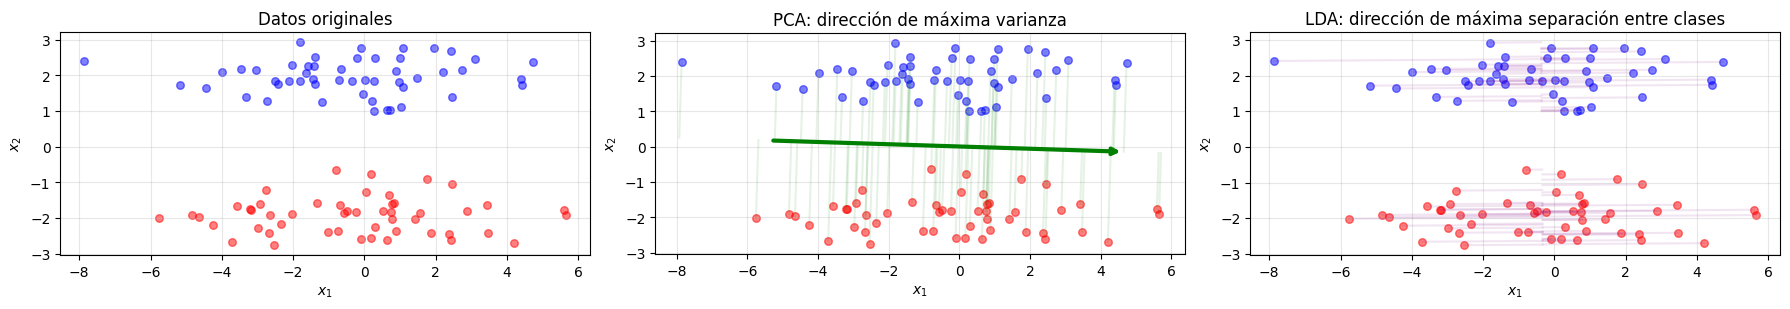

PCA PC1 direction: (0.999, -0.032) → maximiza varianza TOTAL
LDA LD1 direction: (0.007, -1.000) → maximiza separación ENTRE clases


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Visualización: PCA vs LDA en un caso donde difieren
np.random.seed(42)

# Crear datos donde PCA y LDA dan direcciones diferentes
n = 50
# Clase 0: dispersa horizontalmente
X0 = np.random.randn(n, 2) @ np.array([[3, 0], [0, 0.5]]) + np.array([0, 2])
# Clase 1: dispersa horizontalmente, separada verticalmente
X1 = np.random.randn(n, 2) @ np.array([[3, 0], [0, 0.5]]) + np.array([0, -2])

X_demo = np.vstack([X0, X1])
y_demo = np.array([0]*n + [1]*n)

# PCA
mean_all = X_demo.mean(axis=0)
X_c = X_demo - mean_all
cov = np.cov(X_c.T)
eigvals_pca, eigvecs_pca = np.linalg.eig(cov)
pc1 = eigvecs_pca[:, np.argmax(eigvals_pca)]

# LDA
mean_0 = X_demo[y_demo == 0].mean(axis=0)
mean_1 = X_demo[y_demo == 1].mean(axis=0)
SW = (X0 - mean_0).T @ (X0 - mean_0) + (X1 - mean_1).T @ (X1 - mean_1)
SB = n * np.outer(mean_0 - mean_all, mean_0 - mean_all) + n * np.outer(mean_1 - mean_all, mean_1 - mean_all)
eigvals_lda, eigvecs_lda = np.linalg.eig(np.linalg.inv(SW) @ SB)
ld1 = eigvecs_lda[:, np.argmax(np.abs(eigvals_lda))].real

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Datos originales
for ax in axes:
    ax.scatter(X0[:, 0], X0[:, 1], color='blue', alpha=0.5, s=30)
    ax.scatter(X1[:, 0], X1[:, 1], color='red', alpha=0.5, s=30)
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.grid(True, alpha=0.3)
    ax.set_aspect('equal')

axes[0].set_title('Datos originales')

# PCA
scale = 5
axes[1].annotate('', xy=mean_all + pc1*scale, xytext=mean_all - pc1*scale,
                 arrowprops=dict(arrowstyle='->', color='green', lw=3))
axes[1].set_title('PCA: dirección de máxima varianza')

# Proyecciones PCA
for x in X_demo:
    proj = mean_all + np.dot(x - mean_all, pc1) * pc1
    axes[1].plot([x[0], proj[0]], [x[1], proj[1]], 'g-', alpha=0.1)

# LDA
axes[2].annotate('', xy=mean_all + ld1*scale, xytext=mean_all - ld1*scale,
                 arrowprops=dict(arrowstyle='->', color='purple', lw=3))
axes[2].set_title('LDA: dirección de máxima separación entre clases')

# Proyecciones LDA
for x in X_demo:
    proj = mean_all + np.dot(x - mean_all, ld1) * ld1
    axes[2].plot([x[0], proj[0]], [x[1], proj[1]], color='purple', alpha=0.1)

plt.tight_layout()
plt.show()

print(f"PCA PC1 direction: ({pc1[0]:.3f}, {pc1[1]:.3f}) → maximiza varianza TOTAL")
print(f"LDA LD1 direction: ({ld1[0]:.3f}, {ld1[1]:.3f}) → maximiza separación ENTRE clases")

### Ejemplo numérico

Apliquemos LDA paso a paso a nuestros datos simples (2D → 1D con 2 clases).

| $x_1$ | $x_2$ | Clase |
|-------|-------|-------|
| 1     | 2     | 0     |
| 2     | 3     | 0     |
| 3     | 3     | 0     |
| 2     | 1     | 0     |
| 6     | 7     | 1     |
| 7     | 8     | 1     |
| 8     | 7     | 1     |
| 7     | 6     | 1     |

**Paso 1: Calcular medias**

$$
\boldsymbol{\mu}_0 = (2.0, \ 2.25), \quad \boldsymbol{\mu}_1 = (7.0, \ 7.0), \quad \boldsymbol{\mu} = (4.5, \ 4.625)
$$

**Paso 2: Calcular $\mathbf{S}_W$**

Para la clase 0:

$$
\mathbf{S}_{W_0} = \sum_{\mathbf{x}_i \in C_0}(\mathbf{x}_i - \boldsymbol{\mu}_0)(\mathbf{x}_i - \boldsymbol{\mu}_0)^T
$$

Calculando cada término y sumando: $\mathbf{S}_{W_0} = \begin{pmatrix} 2 & 1 \\ 1 & 3.75 \end{pmatrix}$

Para la clase 1: $\mathbf{S}_{W_1} = \begin{pmatrix} 2 & -1 \\ -1 & 2 \end{pmatrix}$

$$
\mathbf{S}_W = \mathbf{S}_{W_0} + \mathbf{S}_{W_1} = \begin{pmatrix} 4 & 0 \\ 0 & 5.75 \end{pmatrix}
$$

**Paso 3: Calcular $\mathbf{S}_B$**

$$
\boldsymbol{\mu}_0 - \boldsymbol{\mu} = (-2.5, -2.375), \quad \boldsymbol{\mu}_1 - \boldsymbol{\mu} = (2.5, 2.375)
$$

$$
\mathbf{S}_B = 4 \cdot (-2.5, -2.375)^T(-2.5, -2.375) + 4 \cdot (2.5, 2.375)^T(2.5, 2.375)
$$

$$
= \begin{pmatrix} 50 & 47.5 \\ 47.5 & 45.125 \end{pmatrix}
$$

**Paso 4: Resolver el problema eigen de $\mathbf{S}_W^{-1}\mathbf{S}_B$**

$$
\mathbf{S}_W^{-1}\mathbf{S}_B \mathbf{w} = \lambda \mathbf{w}
$$

El eigenvector con mayor eigenvalor nos da el discriminante lineal: la dirección óptima para separar las dos clases.

In [ ]:
import numpy as np

X = np.array([[1, 2], [2, 3], [3, 3], [2, 1],
              [6, 7], [7, 8], [8, 7], [7, 6]], dtype=np.float64)
y = np.array([0, 0, 0, 0, 1, 1, 1, 1])

print("=== Ejemplo numérico: LDA paso a paso ===")

# Paso 1: Medias
mean_0 = X[y == 0].mean(axis=0)
mean_1 = X[y == 1].mean(axis=0)
mean_all = X.mean(axis=0)

print(f"\nPaso 1 - Medias:")
print(f"  μ₀ = ({mean_0[0]:.2f}, {mean_0[1]:.2f})")
print(f"  μ₁ = ({mean_1[0]:.2f}, {mean_1[1]:.2f})")
print(f"  μ  = ({mean_all[0]:.2f}, {mean_all[1]:.2f})")

# Paso 2: SW
X_0 = X[y == 0]
X_1 = X[y == 1]
SW = (X_0 - mean_0).T @ (X_0 - mean_0) + (X_1 - mean_1).T @ (X_1 - mean_1)

print(f"\nPaso 2 - SW (within-class scatter):")
print(f"  [{SW[0,0]:.2f}  {SW[0,1]:.2f}]")
print(f"  [{SW[1,0]:.2f}  {SW[1,1]:.2f}]")

# Paso 3: SB
n_0, n_1 = len(X_0), len(X_1)
diff_0 = (mean_0 - mean_all).reshape(-1, 1)
diff_1 = (mean_1 - mean_all).reshape(-1, 1)
SB = n_0 * diff_0 @ diff_0.T + n_1 * diff_1 @ diff_1.T

print(f"\nPaso 3 - SB (between-class scatter):")
print(f"  [{SB[0,0]:.2f}  {SB[0,1]:.2f}]")
print(f"  [{SB[1,0]:.2f}  {SB[1,1]:.2f}]")

# Paso 4: Eigenvalores
A = np.linalg.inv(SW) @ SB
eigenvalues, eigenvectors = np.linalg.eig(A)

# Ordenar
eigenvectors = eigenvectors.T
idxs = np.argsort(np.abs(eigenvalues))[::-1]
eigenvalues = eigenvalues[idxs].real
eigenvectors = eigenvectors[idxs].real

print(f"\nPaso 4 - Eigen de SW⁻¹SB:")
print(f"  Eigenvalores: λ₁ = {eigenvalues[0]:.4f}, λ₂ = {eigenvalues[1]:.4f}")
print(f"  LD1 = ({eigenvectors[0, 0]:.4f}, {eigenvectors[0, 1]:.4f})")

# Paso 5: Proyectar
ld1 = eigenvectors[0]
X_1d = X @ ld1

print(f"\nPaso 5 - Datos proyectados a 1D:")
for i, (orig, proj) in enumerate(zip(X, X_1d)):
    label = 'Clase 0' if y[i] == 0 else 'Clase 1'
    print(f"  ({orig[0]:.0f}, {orig[1]:.0f}) → {proj:.4f}  [{label}]")

=== Ejemplo numérico: LDA paso a paso ===

Paso 1 - Medias:
  μ₀ = (2.00, 2.25)
  μ₁ = (7.00, 7.00)
  μ  = (4.50, 4.62)

Paso 2 - SW (within-class scatter):
  [4.00  1.00]
  [1.00  4.75]

Paso 3 - SB (between-class scatter):
  [50.00  47.50]
  [47.50  45.12]

Paso 4 - Eigen de SW⁻¹SB:
  Eigenvalores: λ₁ = 17.9444, λ₂ = 0.0000
  LD1 = (0.8051, 0.5932)

Paso 5 - Datos proyectados a 1D:
  (1, 2) → 1.9915  [Clase 0]
  (2, 3) → 3.3897  [Clase 0]
  (3, 3) → 4.1948  [Clase 0]
  (2, 1) → 2.2033  [Clase 0]
  (6, 7) → 8.9827  [Clase 1]
  (7, 8) → 10.3810  [Clase 1]
  (8, 7) → 10.5928  [Clase 1]
  (7, 6) → 9.1946  [Clase 1]


## Implementación con Código

### Funciones

In [ ]:
import numpy as np

def lda_fit(X, y, n_components):
    """Calcula los discriminantes lineales"""
    n_features = X.shape[1]
    class_labels = np.unique(y)
    mean_overall = np.mean(X, axis=0)

    SW = np.zeros((n_features, n_features))
    SB = np.zeros((n_features, n_features))

    for c in class_labels:
        X_c = X[y == c]
        mean_c = np.mean(X_c, axis=0)

        # Within-class scatter
        SW += (X_c - mean_c).T.dot(X_c - mean_c)

        # Between-class scatter
        n_c = X_c.shape[0]
        mean_diff = (mean_c - mean_overall).reshape(n_features, 1)
        SB += n_c * mean_diff.dot(mean_diff.T)

    # Eigenvalores de SW^-1 * SB
    A = np.linalg.inv(SW).dot(SB)
    eigenvalues, eigenvectors = np.linalg.eig(A)

    eigenvectors = eigenvectors.T
    idxs = np.argsort(abs(eigenvalues))[::-1]
    eigenvalues = eigenvalues[idxs]
    eigenvectors = eigenvectors[idxs]

    linear_discriminants = eigenvectors[:n_components]
    return linear_discriminants, eigenvalues

def lda_transform(X, linear_discriminants):
    """Proyecta los datos al espacio discriminante"""
    return np.dot(X, linear_discriminants.T)

Shape original: (150, 4)
Shape reducido: (150, 2)
Nota: con 3 clases, máximo 2 discriminantes (C-1 = 2)


/tmp/ipython-input-286/2642644729.py:19: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  edgecolor='none', alpha=0.8, cmap=plt.cm.get_cmap('viridis', 3))


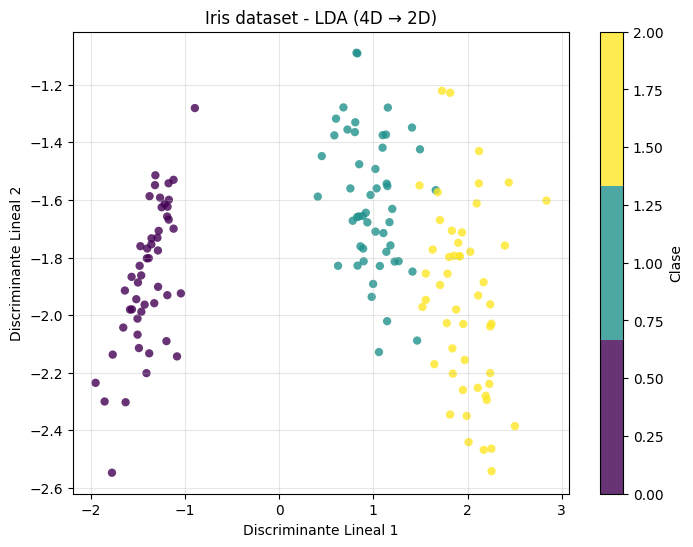

In [ ]:
import matplotlib.pyplot as plt
from sklearn import datasets

# Cargar datos
data = datasets.load_iris()
X, y = data.data, data.target

# Aplicar LDA: de 4D a 2D
linear_discriminants, eigenvalues = lda_fit(X, y, n_components=2)
X_projected = lda_transform(X, linear_discriminants)

print(f"Shape original: {X.shape}")
print(f"Shape reducido: {X_projected.shape}")
print(f"Nota: con 3 clases, máximo 2 discriminantes (C-1 = 2)")

# Graficar
plt.figure(figsize=(8, 6))
plt.scatter(X_projected[:, 0].real, X_projected[:, 1].real, c=y,
            edgecolor='none', alpha=0.8, cmap=plt.cm.get_cmap('viridis', 3))
plt.xlabel('Discriminante Lineal 1')
plt.ylabel('Discriminante Lineal 2')
plt.title('Iris dataset - LDA (4D → 2D)')
plt.colorbar(label='Clase')
plt.grid(True, alpha=0.3)
plt.show()

### Clase

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


class LDA:
    def __init__(self, n_components):
        self.n_components = n_components
        self.linear_discriminants = None
        self.eigenvalues = None

    def fit(self, X, y):
        """Calcula los discriminantes lineales"""
        n_features = X.shape[1]
        class_labels = np.unique(y)

        mean_overall = np.mean(X, axis=0)
        SW = np.zeros((n_features, n_features))
        SB = np.zeros((n_features, n_features))

        for c in class_labels:
            X_c = X[y == c]
            mean_c = np.mean(X_c, axis=0)

            # Within-class scatter
            SW += (X_c - mean_c).T.dot(X_c - mean_c)

            # Between-class scatter
            n_c = X_c.shape[0]
            mean_diff = (mean_c - mean_overall).reshape(n_features, 1)
            SB += n_c * mean_diff.dot(mean_diff.T)

        # Eigenvalores de SW^-1 * SB
        A = np.linalg.inv(SW).dot(SB)
        eigenvalues, eigenvectors = np.linalg.eig(A)

        eigenvectors = eigenvectors.T
        idxs = np.argsort(abs(eigenvalues))[::-1]
        self.eigenvalues = eigenvalues[idxs].real
        eigenvectors = eigenvectors[idxs].real

        self.linear_discriminants = eigenvectors[:self.n_components]

    def transform(self, X):
        """Proyecta los datos al espacio discriminante"""
        return np.dot(X, self.linear_discriminants.T)

    def fit_transform(self, X, y):
        """fit + transform en un solo paso"""
        self.fit(X, y)
        return self.transform(X)

    def explained_variance_ratio(self):
        """Retorna la proporción de separación capturada por cada componente"""
        total = np.sum(np.abs(self.eigenvalues))
        return np.abs(self.eigenvalues) / total if total > 0 else self.eigenvalues

    def plot_2d_projection(self, X, y, title="Proyección LDA 2D"):
        """Grafica la proyección en 2D (requiere n_components >= 2)"""
        X_proj = self.transform(X)
        n_classes = len(np.unique(y))

        plt.figure(figsize=(8, 6))
        scatter = plt.scatter(X_proj[:, 0], X_proj[:, 1], c=y,
                             edgecolor='none', alpha=0.8,
                             cmap=plt.cm.get_cmap('viridis', n_classes))
        plt.colorbar(scatter, label='Clase')

        ratios = self.explained_variance_ratio()
        plt.xlabel(f'LD1 ({ratios[0]*100:.1f}% separación)')
        plt.ylabel(f'LD2 ({ratios[1]*100:.1f}% separación)')
        plt.title(title)
        plt.grid(True, alpha=0.3)
        plt.show()

Shape original: (150, 4)
Clases: 3 → máximo 2 discriminantes
Shape reducido: (150, 2)

Separación capturada por componente:
  LD1: 99.1%
  LD2: 0.9%


/tmp/ipython-input-286/1527905756.py:65: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap=plt.cm.get_cmap('viridis', n_classes))


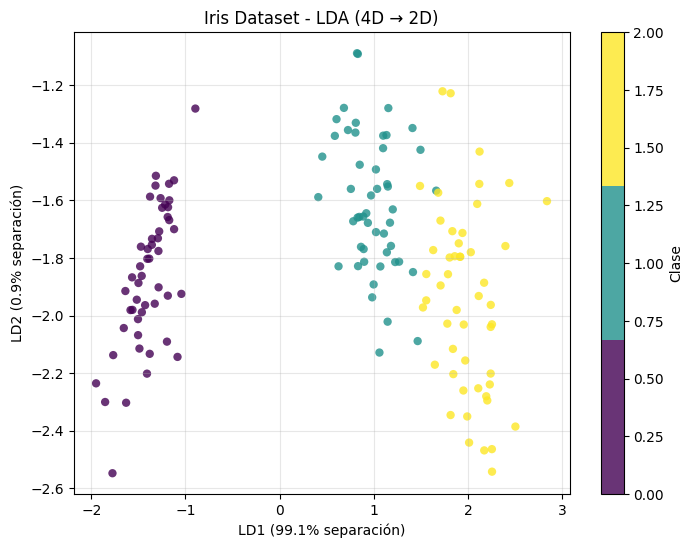

In [ ]:
from sklearn import datasets

# --- Iris dataset ---
data = datasets.load_iris()
X, y = data.data, data.target

print(f"Shape original: {X.shape}")
print(f"Clases: {len(np.unique(y))} → máximo {len(np.unique(y)) - 1} discriminantes")

# Crear y ajustar LDA
lda = LDA(n_components=2)
X_projected = lda.fit_transform(X, y)

print(f"Shape reducido: {X_projected.shape}")
print(f"\nSeparación capturada por componente:")
for i, ratio in enumerate(lda.explained_variance_ratio()[:2]):
    print(f"  LD{i+1}: {ratio*100:.1f}%")

# Visualización
lda.plot_2d_projection(X, y, title="Iris Dataset - LDA (4D → 2D)")

/tmp/ipython-input-286/3248763158.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  edgecolor='none', alpha=0.8, cmap=plt.cm.get_cmap('viridis', 3))
/tmp/ipython-input-286/3248763158.py:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  edgecolor='none', alpha=0.8, cmap=plt.cm.get_cmap('viridis', 3))


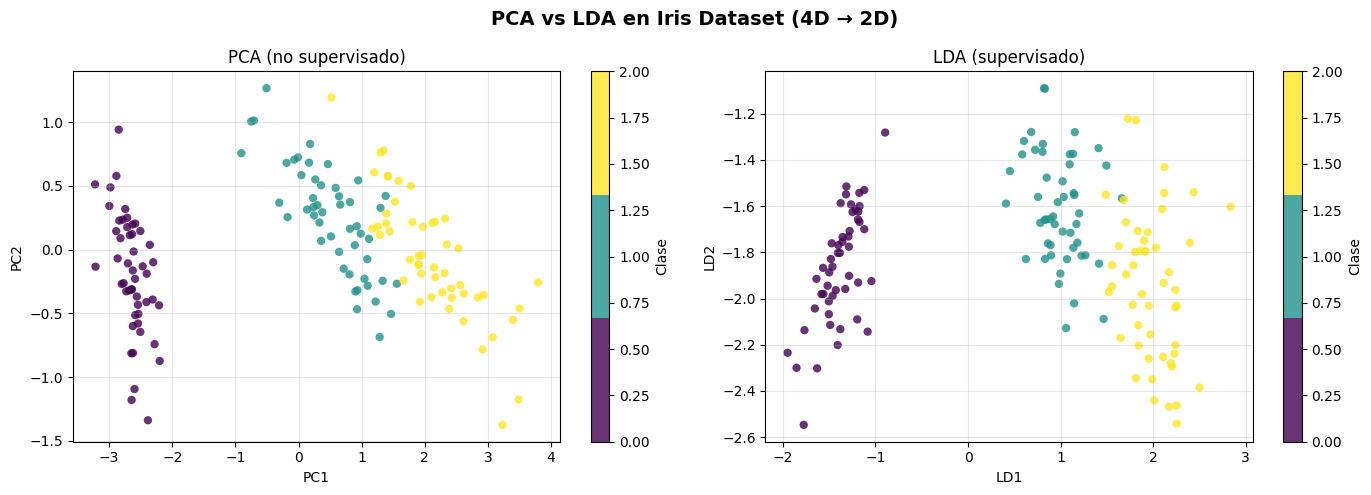

Observar: LDA logra mejor separación entre clases porque usa las etiquetas.


In [ ]:
# --- Comparación PCA vs LDA ---
from sklearn import datasets

data = datasets.load_iris()
X, y = data.data, data.target

# PCA
mean_pca = X.mean(axis=0)
X_c = X - mean_pca
cov = np.cov(X_c.T)
eigvals, eigvecs = np.linalg.eig(cov)
eigvecs = eigvecs.T
idxs = np.argsort(eigvals)[::-1]
eigvecs = eigvecs[idxs]
X_pca = X_c @ eigvecs[:2].T

# LDA
lda = LDA(n_components=2)
X_lda = lda.fit_transform(X, y)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# PCA
sc0 = axes[0].scatter(X_pca[:, 0].real, X_pca[:, 1].real, c=y,
                       edgecolor='none', alpha=0.8, cmap=plt.cm.get_cmap('viridis', 3))
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].set_title('PCA (no supervisado)')
axes[0].grid(True, alpha=0.3)
plt.colorbar(sc0, ax=axes[0], label='Clase')

# LDA
sc1 = axes[1].scatter(X_lda[:, 0], X_lda[:, 1], c=y,
                       edgecolor='none', alpha=0.8, cmap=plt.cm.get_cmap('viridis', 3))
axes[1].set_xlabel('LD1')
axes[1].set_ylabel('LD2')
axes[1].set_title('LDA (supervisado)')
axes[1].grid(True, alpha=0.3)
plt.colorbar(sc1, ax=axes[1], label='Clase')

plt.suptitle('PCA vs LDA en Iris Dataset (4D → 2D)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Observar: LDA logra mejor separación entre clases porque usa las etiquetas.")